Importación de bibliotecas para redes neuronales y optimización (entrenamiento)

In [ ]:
# Import libraries
import torch
import torchvision
from torchvision import transforms, datasets
import torch.nn as nn # Clase NN
import torch.nn.functional as F # Funciones NN
import torch.optim as optim



Creación de los datasets para entrenamiento y validación

In [ ]:
train = datasets.MNIST('./data/', train=True, download=True,
                       transform=transforms.Compose([
                           transforms.ToTensor()
                       ]))

test = datasets.MNIST('./data/', train=False, download=True,
                       transform=transforms.Compose([
                           transforms.ToTensor()
                       ]))



100%|██████████| 9912422/9912422 [00:00<00:00, 173200376.78it/s]

Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw


100%|██████████| 28881/28881 [00:00<00:00, 120893906.01it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw



100%|██████████| 1648877/1648877 [00:00<00:00, 54839715.78it/s]

Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw




100%|██████████| 4542/4542 [00:00<00:00, 3733933.51it/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



Reordenar (shuffle) los datos de entrenamiento para evitar sesgos como consecuencia de un ordenamiento particular.
Además, se define un tamaño para enviar los datos en lotes (batches). Este mecanismo es recomendable para asegurar que la red neuronal no se sobreajuste/sobrentrene a los datos. Para cada tamaño de lote, la red neuronal ejecutará una propagación hacia atrás para obtener nuevos pesos actualizados para intentar disminuir el loss en cada iteración.

In [ ]:
trainset = torch.utils.data.DataLoader(train, batch_size=100, shuffle=True)
testset = torch.utils.data.DataLoader(test, batch_size=100, shuffle=False)

# Ver las dimensiones de los datasets
print("Training dataset shape: ", trainset.dataset.data.shape)
print("Training dataset number of batches: ", len(trainset))
print('--')
print("Testing dataset shape: ", testset.dataset.data.shape)
print("Testing dataset number of batches: ", len(testset))



Training dataset shape:  torch.Size([60000, 28, 28])
Training dataset number of batches:  600
--
Testing dataset shape:  torch.Size([10000, 28, 28])
Testing dataset number of batches:  100


# Creación de la red neuronal como MLP

A su vez se inicializa la red



In [ ]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, 64)
        self.fc4 = nn.Linear(64, 10)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return F.log_softmax(x, dim=1)

net = Net()

# Entrenamiento

In [ ]:
# Configuramos el entrenamiento
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.0001)
training_epochs = 10

losses = []
accur = []

# Entrenamos el modelo
net.train()
for epoch in range(training_epochs): # solo se utilizan 10 épocas paara el entrenamiento
    for j, (X, y) in enumerate(trainset):  # X es el batch de features, y es el batch de targets.

        net.zero_grad()  # setea los gradientes a 0 antes de calcular el loss.

        output = net(X.view(-1,784))  # batch reformateado (imagenes 28x28, el -1 indica que la salida puede tener cualquier número de filas)

        loss = loss_function(output, y) # calcular y obtener el valor del loss

        loss.backward()  # propagar el loss hacia atrás, hacia los parámetros de la ANN

        optimizer.step()  # optimizar los pesos tomando en cuanta el loss y los gradientes


    # Calcular accuracy
    correct = 0
    total = 0
    with torch.no_grad():
      for X, y in testset:
        output = net(X.view(-1,784))
        # print(output)
        for idx, i in enumerate(output):
          if torch.argmax(i) == y[idx]:
            correct += 1
          total += 1

    acc = round(correct/total, 3)
    print("Epoch {}\tLoss : {}\t Accuracy : {}".format(epoch,loss,acc))
    accur.append(acc)

    losses.append(loss.item())


Epoch 0	Loss : 0.6094971299171448	 Accuracy : 0.855
Epoch 1	Loss : 0.3836365044116974	 Accuracy : 0.889
Epoch 2	Loss : 0.32117506861686707	 Accuracy : 0.907
Epoch 3	Loss : 0.3772701621055603	 Accuracy : 0.917
Epoch 4	Loss : 0.24046559631824493	 Accuracy : 0.922
Epoch 5	Loss : 0.16773134469985962	 Accuracy : 0.928
Epoch 6	Loss : 0.32506564259529114	 Accuracy : 0.934
Epoch 7	Loss : 0.1550101339817047	 Accuracy : 0.937
Epoch 8	Loss : 0.1532483696937561	 Accuracy : 0.942
Epoch 9	Loss : 0.16219164431095123	 Accuracy : 0.945


Determinar precisión

In [ ]:
correct = 0
total = 0

with torch.no_grad():
    for data in testset:
        X, y = data
        output = net(X.view(-1,784))
        #print(output)
        for idx, i in enumerate(output):
            #print(torch.argmax(i), y[idx])
            if torch.argmax(i) == y[idx]:
                correct += 1
            total += 1

print("Accuracy: ", round(correct/total, 3))

Accuracy:  0.945


Text(0, 0.5, 'Loss')

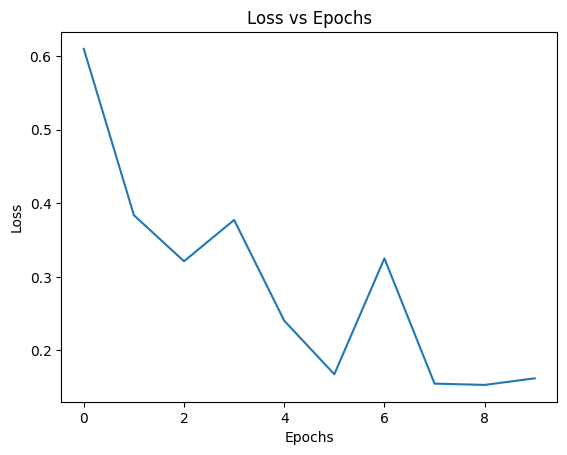

In [ ]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')

Text(0, 0.5, 'Accuracy')

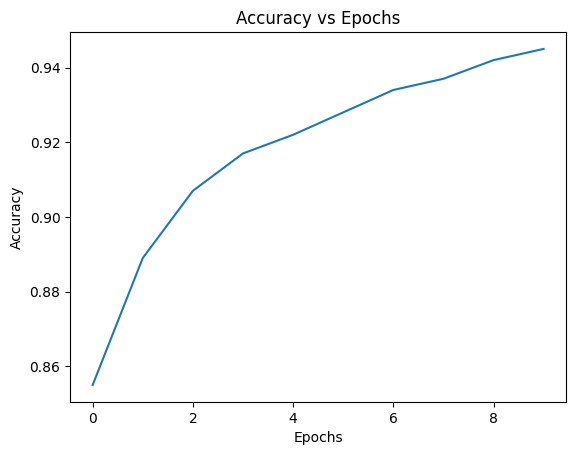

In [ ]:
plt.plot(accur)
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')